# PWV and Arterial Stiffness: Simulation

Effect of wall stiffness on pulse wave velocity (PWV) using the Moens–Korteweg equation, with pressure-wave propagation and a 10 m/s PWV cut-off.

**Simulation only.** Inputs are assumed, no patient data are used, and results are not validated clinical predictions.

## 1. Theory

$$c_0=\sqrt{\frac{E\,h}{2\rho R}}\qquad E=\frac{2\rho R c_0^2}{h}$$

$E$: incremental elastic modulus, $h$: wall thickness, $R$: inner radius, $\rho$: blood density.
Assumes a thin wall ($h/R\lesssim0.1$), linear elasticity, inviscid blood and no reflections.

Cut-off: carotid–femoral PWV > 10 m/s (2012 expert consensus, 80% of direct distance). It is a screening threshold, not age-adjusted and not a diagnosis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

MMHG = 133.322

rho = 1060.0
R = 0.0125
h = 0.0012
E_normal = 1.0e6
E_stiff = 2.5e6

PWV_THRESHOLD = 10.0

f = 1.25
T = 1.0 / f
P_DIA = 80.0 * MMHG
PULSE_PRESSURE = 40.0 * MMHG
L_DIRECT = 0.60
L_EFF = 0.8 * L_DIRECT


def moens_korteweg_pwv(E, h, R, rho):
    E, h, R, rho = map(np.asarray, (E, h, R, rho))
    return np.sqrt(E * h / (2.0 * rho * R))


def critical_modulus(c, h, R, rho):
    return 2.0 * rho * R * c**2 / h


def bramwell_hill_pwv(E, h, R, rho, dP=1.0):
    area = lambda P: np.pi * (R + P * R**2 / (E * h)) ** 2
    dA_dP = (area(dP) - area(-dP)) / (2.0 * dP)
    return np.sqrt(area(0.0) / (rho * dA_dP))


def classify(pwv, threshold=PWV_THRESHOLD):
    return "Elevated PWV (> 10 m/s)" if pwv > threshold else "Below 10 m/s cut-off"


assert h / R <= 0.1
print(f"h/R = {h / R:.3f}, heart rate = {60 * f:.0f} bpm, T = {T:.2f} s, travelled distance = {L_EFF:.2f} m")

h/R = 0.096, heart rate = 75 bpm, T = 0.80 s, travelled distance = 0.48 m


## 2. PWV and classification

In [2]:
PWV_normal = float(moens_korteweg_pwv(E_normal, h, R, rho))
PWV_stiff = float(moens_korteweg_pwv(E_stiff, h, R, rho))

assert np.isclose(PWV_normal, bramwell_hill_pwv(E_normal, h, R, rho), rtol=1e-9)
assert np.isclose(PWV_stiff, bramwell_hill_pwv(E_stiff, h, R, rho), rtol=1e-9)
assert np.isclose(PWV_stiff / PWV_normal, np.sqrt(E_stiff / E_normal), rtol=1e-12)
assert np.isclose(critical_modulus(PWV_normal, h, R, rho), E_normal, rtol=1e-12)

E_crit = float(critical_modulus(PWV_THRESHOLD, h, R, rho))
risk_normal = classify(PWV_normal)
risk_stiff = classify(PWV_stiff)

print(f"Compliant (E = {E_normal/1e6:.2f} MPa): {PWV_normal:5.2f} m/s -> {risk_normal}")
print(f"Stiffened (E = {E_stiff/1e6:.2f} MPa): {PWV_stiff:5.2f} m/s -> {risk_stiff}")
print(f"E at the cut-off: {E_crit/1e6:.2f} MPa")

assert PWV_normal < PWV_THRESHOLD < PWV_stiff
assert E_normal < E_crit < E_stiff

Compliant (E = 1.00 MPa):  6.73 m/s -> Below 10 m/s cut-off
Stiffened (E = 2.50 MPa): 10.64 m/s -> Elevated PWV (> 10 m/s)
E at the cut-off: 2.21 MPa


## 3. Sensitivity

The label near the cut-off depends strongly on the assumed inputs.

Stiffened artery, base PWV = 10.64 m/s
parameter                  -20 %                 +20 %
E               9.52 m/s (<= 10)      11.66 m/s (> 10)
h               9.52 m/s (<= 10)      11.66 m/s (> 10)
R               11.90 m/s (> 10)      9.71 m/s (<= 10)
rho             11.90 m/s (> 10)      9.71 m/s (<= 10)


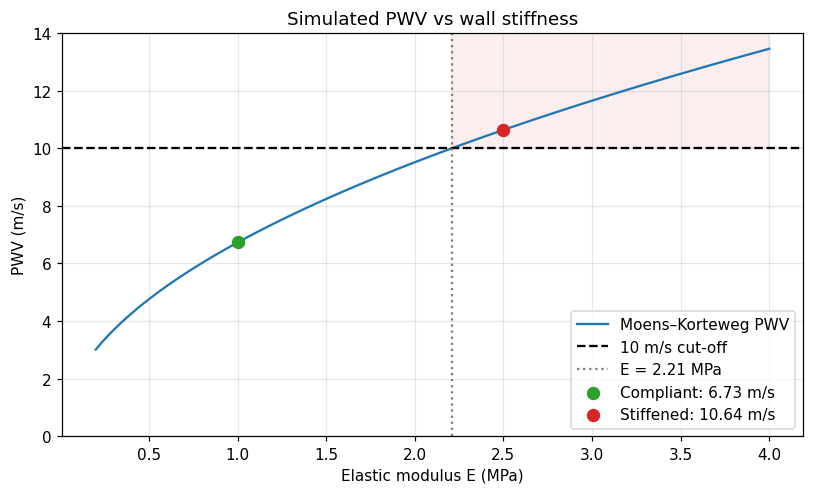

In [3]:
base = dict(E=E_stiff, h=h, R=R, rho=rho)
print(f"Stiffened artery, base PWV = {PWV_stiff:.2f} m/s")
print(f"{'parameter':<10}{'-20 %':>22}{'+20 %':>22}")
for name in ["E", "h", "R", "rho"]:
    out = []
    for factor in (0.8, 1.2):
        p = dict(base)
        p[name] = base[name] * factor
        v = float(moens_korteweg_pwv(**p))
        out.append(f"{v:5.2f} m/s ({'>' if v > PWV_THRESHOLD else '<='} 10)")
    print(f"{name:<10}{out[0]:>22}{out[1]:>22}")

E_axis = np.linspace(0.2e6, 4.0e6, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(E_axis / 1e6, moens_korteweg_pwv(E_axis, h, R, rho), color="tab:blue", label="Moens–Korteweg PWV")
ax.axhline(PWV_THRESHOLD, color="k", ls="--", label="10 m/s cut-off")
ax.axvline(E_crit / 1e6, color="gray", ls=":", label=f"E = {E_crit/1e6:.2f} MPa")
ax.fill_between(E_axis / 1e6, PWV_THRESHOLD, 14, where=E_axis > E_crit, color="tab:red", alpha=0.08)
ax.scatter([E_normal / 1e6], [PWV_normal], color="tab:green", zorder=5, s=60, label=f"Compliant: {PWV_normal:.2f} m/s")
ax.scatter([E_stiff / 1e6], [PWV_stiff], color="tab:red", zorder=5, s=60, label=f"Stiffened: {PWV_stiff:.2f} m/s")
ax.set_xlabel("Elastic modulus E (MPa)")
ax.set_ylabel("PWV (m/s)")
ax.set_ylim(0, 14)
ax.set_title("Simulated PWV vs wall stiffness")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Pressure-wave simulation

Forward-travelling wave $P(x,t)=P_{\mathrm{ref}}(t-x/c_0)$ with a 120/80 mmHg pulse. The same waveform is used for both cases; no reflection or damping.

In [4]:
def _wrap(d):
    return (d + 0.5) % 1.0 - 0.5


def _raw_pulse(tau):
    systolic = np.exp(-0.5 * (_wrap(tau - 0.17) / 0.07) ** 2)
    late = 0.45 * np.exp(-0.5 * (_wrap(tau - 0.42) / 0.10) ** 2)
    return systolic + late


_tau = np.linspace(0.0, 1.0, 20001, endpoint=False)
_lo, _hi = _raw_pulse(_tau).min(), _raw_pulse(_tau).max()


def pressure_ref(t):
    tau = (np.asarray(t) * f) % 1.0
    return P_DIA + PULSE_PRESSURE * (_raw_pulse(tau) - _lo) / (_hi - _lo)


def pressure_xt(t, x, c):
    return pressure_ref(np.asarray(t) - np.asarray(x) / c)


P_all = pressure_ref(_tau / f)
print(f"Pressure range: {P_all.min()/MMHG:.1f} to {P_all.max()/MMHG:.1f} mmHg")
assert P_all.min() > 0 and np.isclose(P_all.min() / MMHG, 80, atol=0.1) and np.isclose(P_all.max() / MMHG, 120, atol=0.1)
for name, c in [("compliant", PWV_normal), ("stiffened", PWV_stiff)]:
    print(f"Wavelength ({name}): {c / f:.1f} m")

Pressure range: 80.0 to 120.0 mmHg
Wavelength (compliant): 5.4 m
Wavelength (stiffened): 8.5 m


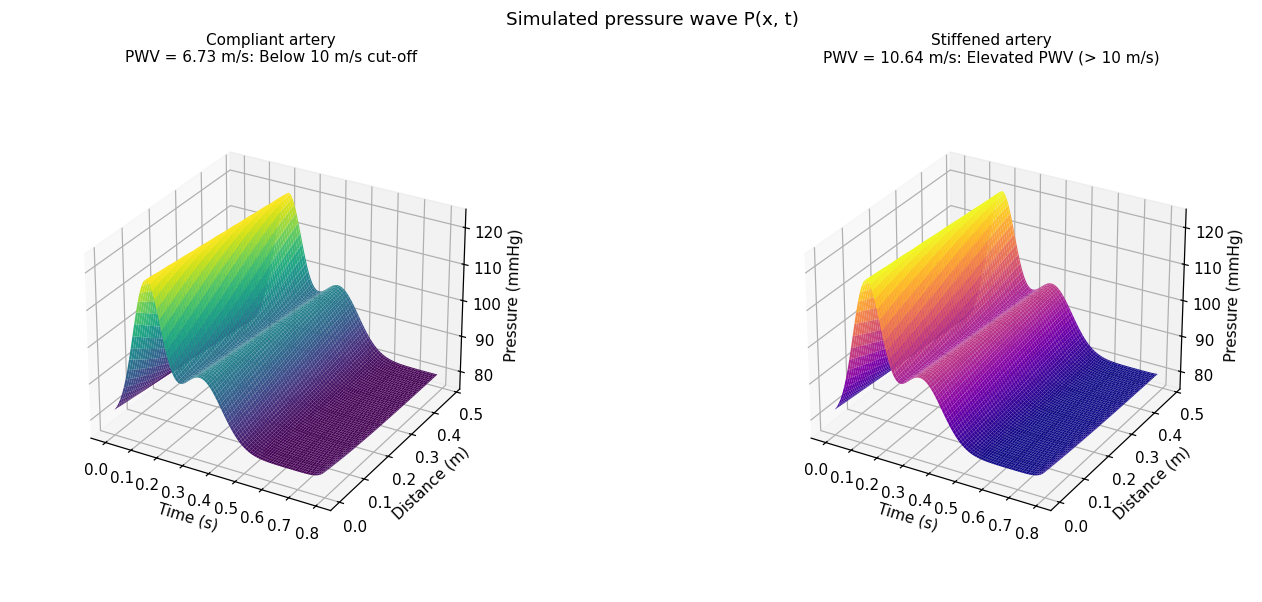

In [5]:
x_grid = np.linspace(0.0, L_EFF, 120)
t_beat = np.linspace(0.0, T, 200, endpoint=False)

P_normal = pressure_xt(t_beat[None, :], x_grid[:, None], PWV_normal) / MMHG
P_stiff = pressure_xt(t_beat[None, :], x_grid[:, None], PWV_stiff) / MMHG
Tm, Xm = np.meshgrid(t_beat, x_grid)

fig = plt.figure(figsize=(13, 5.5))
for k, (P, cmap, title, c, cat) in enumerate([
        (P_normal, "viridis", "Compliant artery", PWV_normal, risk_normal),
        (P_stiff, "plasma", "Stiffened artery", PWV_stiff, risk_stiff)], start=1):
    ax = fig.add_subplot(1, 2, k, projection="3d")
    ax.plot_surface(Tm, Xm, P, cmap=cmap, rcount=80, ccount=120, linewidth=0, antialiased=True)
    ax.set_title(f"{title}\nPWV = {c:.2f} m/s: {cat}", fontsize=10)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Distance (m)")
    ax.set_zlabel("Pressure (mmHg)")
    ax.set_zlim(75, 125)
    ax.view_init(elev=28, azim=-60)
    ax.set_box_aspect(None, zoom=0.82)
fig.suptitle("Simulated pressure wave P(x, t)", y=0.98)
fig.subplots_adjust(left=0.0, right=0.97, bottom=0.02, top=0.88, wspace=0.08)
plt.show()

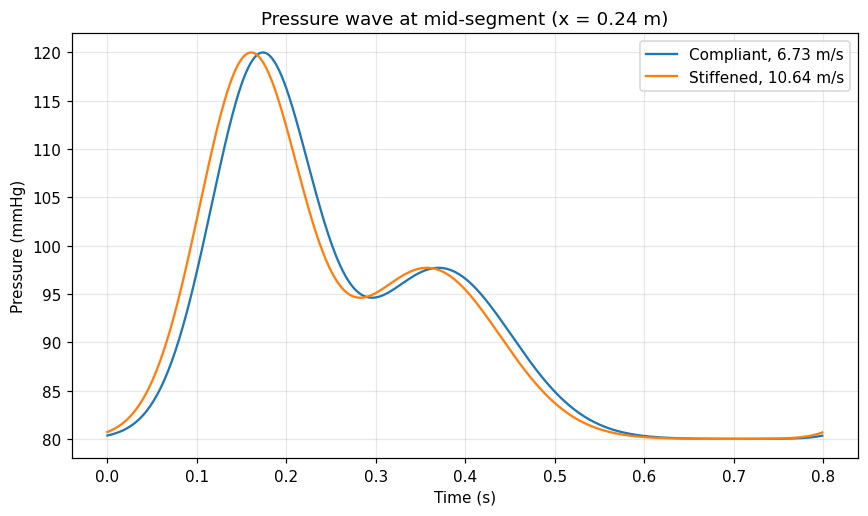

Mid-segment delay: 35.7 ms (compliant), 22.6 ms (stiffened)


In [6]:
mid = L_EFF / 2.0
t_plot = np.linspace(0.0, T, 600, endpoint=False)

plt.figure(figsize=(8, 4.8))
plt.plot(t_plot, pressure_xt(t_plot, mid, PWV_normal) / MMHG, label=f"Compliant, {PWV_normal:.2f} m/s")
plt.plot(t_plot, pressure_xt(t_plot, mid, PWV_stiff) / MMHG, label=f"Stiffened, {PWV_stiff:.2f} m/s")
plt.xlabel("Time (s)")
plt.ylabel("Pressure (mmHg)")
plt.title(f"Pressure wave at mid-segment (x = {mid:.2f} m)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Mid-segment delay: {mid/PWV_normal*1e3:.1f} ms (compliant), {mid/PWV_stiff*1e3:.1f} ms (stiffened)")

## 5. PWV from simulated waveforms

PWV = distance / transit time between a proximal and a distal site, using the foot-to-foot method (10% of pulse amplitude) and cross-correlation.

In [7]:
FS = 2000
N_PER_BEAT = int(round(FS * T))
t_long = np.arange(3 * N_PER_BEAT) / FS


def foot_time(t, p, beat_index=1, level=0.10):
    y = P_DIA + level * PULSE_PRESSURE
    idx = np.where((p[:-1] < y) & (p[1:] >= y))[0]
    assert len(idx) >= beat_index + 1
    i = idx[beat_index]
    return t[i] + (y - p[i]) / (p[i + 1] - p[i]) * (t[i + 1] - t[i])


def xcorr_delay(p_prox, p_dist, fs):
    a = p_prox - p_prox.mean()
    b = p_dist - p_dist.mean()
    r = np.fft.irfft(np.conj(np.fft.rfft(a)) * np.fft.rfft(b), n=len(a))
    k = int(np.argmax(r))
    y0, ym, yp = r[k], r[k - 1], r[(k + 1) % len(r)]
    delta = 0.5 * (ym - yp) / (ym - 2 * y0 + yp)
    return (k + delta) / fs


def measure_pwv(c):
    p_prox = pressure_xt(t_long, 0.0, c)
    p_dist = pressure_xt(t_long, L_EFF, c)
    dt_foot = foot_time(t_long, p_dist) - foot_time(t_long, p_prox)
    one = slice(N_PER_BEAT, 2 * N_PER_BEAT)
    dt_xc = xcorr_delay(p_prox[one], p_dist[one], FS)
    return dict(p_prox=p_prox, p_dist=p_dist, dt_foot=dt_foot, dt_xc=dt_xc,
                pwv_foot=L_EFF / dt_foot, pwv_xc=L_EFF / dt_xc)


meas_normal = measure_pwv(PWV_normal)
meas_stiff = measure_pwv(PWV_stiff)

for name, c, m in [("Compliant", PWV_normal, meas_normal), ("Stiffened", PWV_stiff, meas_stiff)]:
    err_f = 100 * (m["pwv_foot"] - c) / c
    err_x = 100 * (m["pwv_xc"] - c) / c
    print(f"{name:<10} analytic {c:5.2f} | foot-to-foot {m['pwv_foot']:5.2f} (dt = {m['dt_foot']*1e3:5.1f} ms, {err_f:+.2f} %)"
          f" | cross-corr {m['pwv_xc']:5.2f} (dt = {m['dt_xc']*1e3:5.1f} ms, {err_x:+.2f} %)")
    assert abs(err_f) < 1.0 and abs(err_x) < 1.0

assert classify(meas_normal["pwv_foot"]) == risk_normal and classify(meas_stiff["pwv_foot"]) == risk_stiff
assert classify(meas_normal["pwv_xc"]) == risk_normal and classify(meas_stiff["pwv_xc"]) == risk_stiff

Compliant  analytic  6.73 | foot-to-foot  6.73 (dt =  71.3 ms, -0.00 %) | cross-corr  6.73 (dt =  71.3 ms, -0.00 %)
Stiffened  analytic 10.64 | foot-to-foot 10.64 (dt =  45.1 ms, -0.00 %) | cross-corr 10.64 (dt =  45.1 ms, +0.00 %)


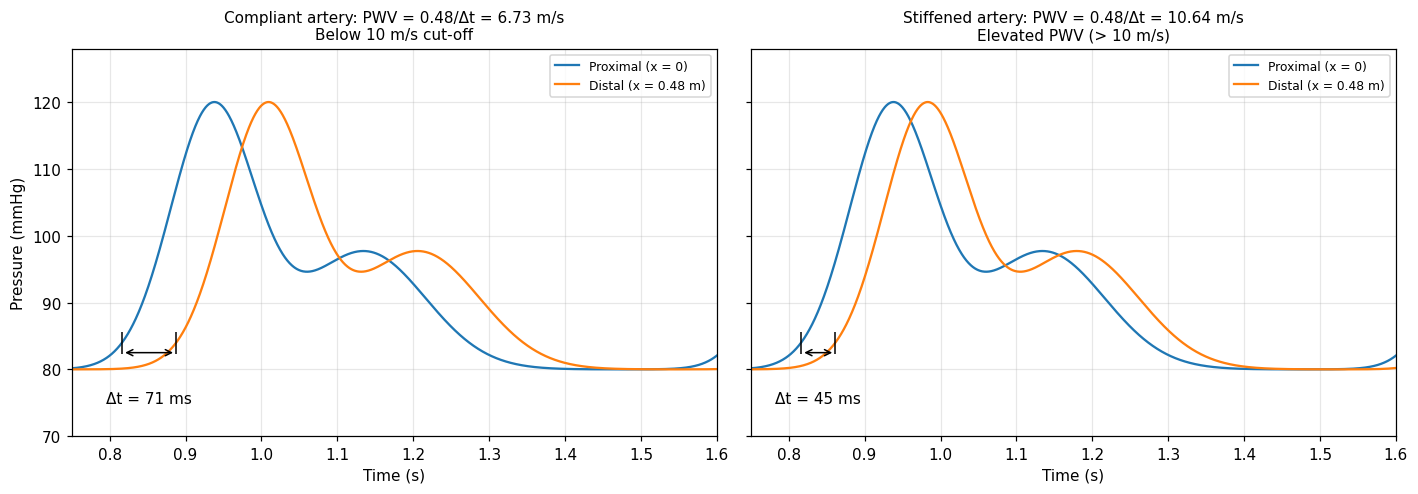

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, title, m, cat in [(axes[0], "Compliant artery", meas_normal, risk_normal),
                          (axes[1], "Stiffened artery", meas_stiff, risk_stiff)]:
    ax.plot(t_long, m["p_prox"] / MMHG, label="Proximal (x = 0)")
    ax.plot(t_long, m["p_dist"] / MMHG, label=f"Distal (x = {L_EFF:.2f} m)")
    tf_p = foot_time(t_long, m["p_prox"])
    tf_d = foot_time(t_long, m["p_dist"])
    y_foot = (P_DIA + 0.10 * PULSE_PRESSURE) / MMHG
    ax.plot([tf_p, tf_d], [y_foot, y_foot], "k|", ms=14)
    ax.annotate("", xy=(tf_d, y_foot - 1.5), xytext=(tf_p, y_foot - 1.5), arrowprops=dict(arrowstyle="<->", color="k"))
    ax.text((tf_p + tf_d) / 2, y_foot - 9.0, f"Δt = {m['dt_foot']*1e3:.0f} ms", ha="center")
    ax.set_xlim(T - 0.05, 2 * T)
    ax.set_title(f"{title}: PWV = {L_EFF}/Δt = {m['pwv_foot']:.2f} m/s\n{cat}", fontsize=10)
    ax.set_xlabel("Time (s)")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("Pressure (mmHg)")
axes[0].set_ylim(70, 128)
plt.tight_layout()
plt.show()

### Timing and distance error

In [9]:
print(f"{'case':<11}{'true dt':>9}{'-5 ms':>16}{'+5 ms':>16}")
for name, m in [("Compliant", meas_normal), ("Stiffened", meas_stiff)]:
    dt = m["dt_foot"]
    cols = []
    for err in (-0.005, +0.005):
        v = L_EFF / (dt + err)
        cols.append(f"{v:5.2f} ({'>' if v > PWV_THRESHOLD else '<='} 10)")
    print(f"{name:<11}{dt*1e3:7.1f} ms{cols[0]:>16}{cols[1]:>16}")

print(f"\nUsing the full direct distance ({L_DIRECT:.2f} m) instead of 80% raises PWV by {100*(L_DIRECT/L_EFF-1):.0f}% "
      f"({meas_normal['pwv_foot']*L_DIRECT/L_EFF:.2f} and {meas_stiff['pwv_foot']*L_DIRECT/L_EFF:.2f} m/s).")

case         true dt           -5 ms           +5 ms
Compliant     71.3 ms    7.24 (<= 10)    6.29 (<= 10)
Stiffened     45.1 ms    11.97 (> 10)    9.58 (<= 10)

Using the full direct distance (0.60 m) instead of 80% raises PWV by 25% (8.41 and 13.30 m/s).


## 6. Summary

In [10]:
rows = [("Compliant artery", E_normal, PWV_normal, meas_normal),
        ("Stiffened artery", E_stiff, PWV_stiff, meas_stiff)]

print(f"R = {R*1e3:.1f} mm, h = {h*1e3:.1f} mm, rho = {rho:.0f} kg/m^3, cut-off = {PWV_THRESHOLD:.0f} m/s (E = {E_crit/1e6:.2f} MPa)\n")
print(f"{'Case':<18}{'E (MPa)':>8}{'PWV MK':>9}{'PWV foot':>10}{'PWV xcorr':>11}   Category")
print("-" * 80)
for name, E, c, m in rows:
    print(f"{name:<18}{E/1e6:8.2f}{c:9.2f}{m['pwv_foot']:10.2f}{m['pwv_xc']:11.2f}   {classify(c)}")

print(f"""
- E increased by {E_stiff/E_normal:.1f}x, PWV increased by {PWV_stiff/PWV_normal:.2f}x (square root of the E ratio).
- The compliant case is below the {PWV_THRESHOLD:.0f} m/s cut-off and the stiffened case is above it.
- The distal pulse arrives {1e3*(meas_normal['dt_foot']-meas_stiff['dt_foot']):.0f} ms earlier in the stiffened case.
- Simulated results only: inputs are assumed, and sensitivity and specificity were not evaluated.
""")

R = 12.5 mm, h = 1.2 mm, rho = 1060 kg/m^3, cut-off = 10 m/s (E = 2.21 MPa)

Case               E (MPa)   PWV MK  PWV foot  PWV xcorr   Category
--------------------------------------------------------------------------------
Compliant artery      1.00     6.73      6.73       6.73   Below 10 m/s cut-off
Stiffened artery      2.50    10.64     10.64      10.64   Elevated PWV (> 10 m/s)

- E increased by 2.5x, PWV increased by 1.58x (square root of the E ratio).
- The compliant case is below the 10 m/s cut-off and the stiffened case is above it.
- The distal pulse arrives 26 ms earlier in the stiffened case.
- Simulated results only: inputs are assumed, and sensitivity and specificity were not evaluated.



## 7. Limitations

- Thin-wall, linear, constant-$E$ model with uniform geometry, no reflections or damping.
- $E$, $R$, $h$ and the waveform are assumed values.
- 10 m/s applies to measured carotid–femoral PWV, not to model output.
- Clinical claims would need measured PWV with a reference standard in a cohort.
